# Студенттердің үлгерімін болжау (Student Performance Prediction)
### Машиналық оқыту бойынша жеке жоба — 2-нұсқа

**Орындаған:** Ораз Ерсұлтан Ершатұлы
**Деректер:** `Student.csv` (1020 жазба, 16 баған)
**Орта:** Google Colab / Jupyter Notebook

**Мазмұны**
1. Есептің қойылымы
2. Деректерді жүктеу және алғашқы шолу
3. Деректердің сапасын зерттеу
4. Деректерді тазалау
5. Барлаушы талдау (EDA) және зерттеу сұрақтары
6. Деректерді модельге дайындау
7. Модельдерді құру (Linear Regression, Decision Tree, Random Forest, Gradient Boosting)
8. Модельдерді бағалау және салыстыру
9. Қателерді талдау
10. Нәтижені интерпретациялау (белгілердің маңыздылығы)
11. Жаңа деректерде тексеру
12. Қорытынды
13. Пайдаланылған дереккөздер

## 1. Есептің қойылымы

**Деректер жиынының мақсаты.** Деректер жиынында студенттердің өмір салты мен оқу әдеттері (күніне оқуға жұмсайтын уақыты, әлеуметтік желі мен Netflix-ке кететін уақыт, ұйқы, тамақтану, спорт, сабаққа қатысу, психикалық жағдай, ата-ананың білімі т.б.) және олардың **емтихан бағасы** (`exam_score`) жазылған.

**Практикалық мәселе (өз сөзіммен).** Университет немесе эдвайзер студенттің емтиханды қалай тапсыратынын алдын ала білгісі келеді: егер студенттің әдеттері бойынша төмен балл болжанса, оған ертерек көмек көрсетуге (кеңес беру, оқу жоспарын түзету) болады. Сонымен қатар қандай әдеттер бағаға шын мәнінде әсер ететінін түсіну маңызды — сонда кеңестер дәлелді болады.

**Мақсатты көрсеткіш:** `exam_score` — емтихан бағасы (0–100 шкаласы). Бұл үздіксіз сандық шама, сондықтан есеп — **регрессия**.

**Негізгі айнымалылар:**

| Баған | Мағынасы | Түрі |
|---|---|---|
| `student_id` | Студент идентификаторы | мәтін (модельге кірмейді) |
| `age` | Жасы | сандық |
| `gender` | Жынысы | категориялық |
| `study_hours_per_day` | Күніне оқуға жұмсалатын сағат | сандық |
| `social_media_hours` | Әлеуметтік желіге жұмсалатын сағат | сандық |
| `netflix_hours` | Netflix/сериалға жұмсалатын сағат | сандық |
| `part_time_job` | Жартылай жұмыс бар ма | бинарлы |
| `attendance_percentage` | Сабаққа қатысу пайызы | сандық |
| `sleep_hours` | Ұйқы сағаты | сандық |
| `diet_quality` | Тамақтану сапасы (Poor/Fair/Good) | реттік |
| `exercise_frequency` | Аптасына спортпен айналысу саны | сандық |
| `parental_education_level` | Ата-ананың білімі | реттік |
| `internet_quality` | Интернет сапасы (Poor/Average/Good) | реттік |
| `mental_health_rating` | Психикалық жағдай бағасы (1–10) | сандық |
| `extracurricular_participation` | Сабақтан тыс іс-шараға қатысу | бинарлы |
| `exam_score` | **Емтихан бағасы — мақсат** | сандық |

**Зерттеу сұрақтарым:**
1. Оқуға жұмсалған уақыт емтихан бағасына қаншалықты күшті әсер етеді және бұл байланыс сызықтық па?
2. «Экран уақыты» (әлеуметтік желі + Netflix) бағаны төмендете ме?
3. Психикалық жағдай, ұйқы және спорт сияқты өмір салты факторларының үлесі қандай?
4. Демографиялық белгілер (жас, жыныс, ата-ананың білімі) бағаны болжауға көмектесе ме, әлде маңызы аз ба?

## 2. Деректерді жүктеу және алғашқы шолу

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from sklearn.base import BaseEstimator, RegressorMixin, clone

class ClipRegressor(RegressorMixin, BaseEstimator):
    """Кез келген регрессорды орап, болжамды [0, 100] шкаласына қиып береді
    (емтихан бағасы 100-ден аспайды және 0-ден кем болмайды)."""
    def __init__(self, estimator, low=0, high=100):
        self.estimator, self.low, self.high = estimator, low, high
    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, y)
        return self
    def predict(self, X):
        return np.clip(self.estimator_.predict(X), self.low, self.high)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)

In [2]:
import os
if not os.path.exists('Student.csv'):
    from google.colab import files
    files.upload()   # Student.csv файлын таңдаңыз

df_raw = pd.read_csv('Student.csv')
print('Өлшемі:', df_raw.shape)
df_raw.head()

Өлшемі: (1020, 16)


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1523,23.0,Other,4.0,3.4,3.2,No,83.0,6.6,Good,5,High School,Average,1,No,61.7
1,S1602,20.0,Female,3.6,3.6,0.9,No,72.7,5.9,Poor,2,NaN,NaN,10,Yes,72.9
2,S1526,19.0,Female,2.8,3.1,4.5,No,95.9,6.3,Fair,2,NaN,Good,3,No,40.7
3,S1031,17.0,Other,1.5,3.1,2.6,Yes,96.2,8.0,Fair,4,Bachelor,Average,3,Yes,51.3
4,S1616,17.0,Male,2.6,2.2,0.0,No,83.3,7.0,Fair,1,Bachelor,Good,10,No,79.3


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1020 non-null   object 
 1   age                            1007 non-null   float64
 2   gender                         1009 non-null   object 
 3   study_hours_per_day            1006 non-null   float64
 4   social_media_hours             1020 non-null   float64
 5   netflix_hours                  1020 non-null   float64
 6   part_time_job                  1020 non-null   object 
 7   attendance_percentage          1008 non-null   float64
 8   sleep_hours                    1010 non-null   float64
 9   diet_quality                   1010 non-null   object 
 10  exercise_frequency             1020 non-null   int64  
 11  parental_education_level       926 non-null    object 
 12  internet_quality               1012 non-null   o

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1007.0,20.56,3.49,0.0,18.50,20.00,23.0,99.0
study_hours_per_day,1006.0,3.59,1.85,-2.0,2.52,3.50,4.5,30.0
social_media_hours,1020.0,2.50,1.17,0.0,1.70,2.50,3.3,7.2
netflix_hours,1020.0,1.82,1.08,0.0,1.00,1.80,2.6,5.4
attendance_percentage,1008.0,84.19,10.14,-5.0,78.18,84.50,91.1,150.0
sleep_hours,1010.0,6.49,1.47,-1.0,5.60,6.45,7.3,24.0
exercise_frequency,1020.0,3.08,2.14,-1.0,1.00,3.00,5.0,20.0
mental_health_rating,1020.0,5.46,2.91,-2.0,3.00,5.00,8.0,20.0
exam_score,1011.0,69.61,17.46,-10.0,58.45,70.50,81.6,150.0


**Алғашқы шолудан байқағаным:**
- Деректерде **1020 жазба және 16 баған** бар: 9 сандық, 7 мәтіндік (оның біреуі — `student_id`).
- `describe()` кестесінің өзі деректердің «кір» екенін көрсетеді: `age` минимумы 0, максимумы 99; `study_hours_per_day` −2 мен 30 аралығында (тәулікте 24 сағат қана бар); `attendance_percentage` 150%-ға дейін; `mental_health_rating` 20-ға дейін (шкала 1–10); `exam_score` −10 мен 150 аралығында.
- Бірнеше бағанда бос мәндер бар (Non-Null саны 1020-дан аз).

Сондықтан модель құрмас бұрын деректердің сапасын жүйелі түрде тексеру қажет.

## 3. Деректердің сапасын зерттеу

### 3.1 Бос мәндер (missing values)

,бос мән саны,"үлесі, %"
parental_education_level,94,9.22
study_hours_per_day,14,1.37
age,13,1.27
attendance_percentage,12,1.18
gender,11,1.08
sleep_hours,10,0.98
diet_quality,10,0.98
exam_score,9,0.88
internet_quality,8,0.78


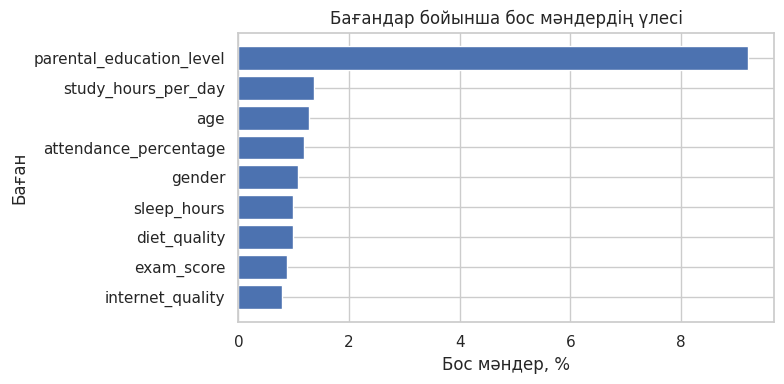

In [5]:
miss = df_raw.isna().sum()
miss = pd.DataFrame({'бос мән саны': miss, 'үлесі, %': (miss / len(df_raw) * 100).round(2)})
miss = miss[miss['бос мән саны'] > 0].sort_values('бос мән саны', ascending=False)
display(miss)

plt.figure(figsize=(8, 4))
plt.barh(miss.index, miss['үлесі, %'], color='#4C72B0')
plt.title('Бағандар бойынша бос мәндердің үлесі')
plt.xlabel('Бос мәндер, %')
plt.ylabel('Баған')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

### 3.2 Қайталанатын жазбалар

In [6]:
print('Толық қайталанатын жолдар:', df_raw.duplicated().sum())
print('Қайталанатын student_id (толық көшірмелерді алып тастағаннан кейін):',
      df_raw.drop_duplicates()['student_id'].duplicated().sum())
same_id = df_raw.drop_duplicates()
same_id[same_id['student_id'].duplicated(keep=False)].sort_values('student_id').head(6)

Толық қайталанатын жолдар: 20
Қайталанатын student_id (толық көшірмелерді алып тастағаннан кейін): 8


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
240,S1006,17.0,Female,3.9,2.4,1.7,Yes,91.0,7.5,Good,4,Master,Average,6,Yes,74.2
396,S1006,21.0,Female,5.6,1.5,1.4,Yes,85.8,6.5,Good,2,Master,Poor,4,No,89.8
272,S1108,23.0,Male,3.1,3.5,2.2,No,78.8,3.4,Fair,0,Master,Good,7,No,49.9
416,S1108,22.0,Female,2.4,1.9,2.1,No,93.3,6.6,poor,4,High School,Average,9,Yes,60.0
348,S1143,21.0,Female,4.8,1.5,2.2,No,87.9,5.9,Fair,4,Bachelor,Poor,2,Yes,78.4
735,S1143,24.0,Male,2.4,2.8,0.7,No,99.8,8.1,Fair,3,NaN,Good,2,No,62.0


### 3.3 Категориялық бағандардағы жазылу сәйкессіздігі

In [7]:
cat_cols = ['gender', 'part_time_job', 'diet_quality', 'parental_education_level',
            'internet_quality', 'extracurricular_participation']
for c in cat_cols:
    print(f'{c}:', df_raw[c].value_counts(dropna=False).to_dict())

gender: {'Female': 480, 'Male': 473, 'Other': 37, nan: 11, ' female ': 7, 'MALE': 6, 'other': 6}
part_time_job: {'No': 797, 'Yes': 211, ' yes': 6, 'NO ': 6}
diet_quality: {'Fair': 434, 'Good': 376, 'Poor': 181, nan: 10, 'fair ': 7, ' GOOD': 6, 'poor': 6}
parental_education_level: {'High School': 401, 'Bachelor': 357, 'Master': 168, nan: 94}
internet_quality: {'Good': 451, 'Average': 389, 'Poor': 154, nan: 8, 'average ': 6, ' GOOD': 6, 'poor': 6}
extracurricular_participation: {'No': 692, 'Yes': 316, ' no ': 6, 'YES': 6}


### 3.4 Мүмкін емес (логикаға қайшы) мәндер

Әр сандық белгі үшін шынайы өмірде мүмкін болатын шекараларды анықтаймыз (мысалы, қатысу 0–100%, күн 24 сағат, психикалық жағдай 1–10 шкаласы) және одан тыс мәндерді табамыз.

In [8]:
valid_ranges = {
    'age':                   (15, 30),   # университет студенттері
    'study_hours_per_day':   (0, 12),
    'social_media_hours':    (0, 16),
    'netflix_hours':         (0, 16),
    'attendance_percentage': (0, 100),
    'sleep_hours':           (3, 12),
    'exercise_frequency':    (0, 7),     # аптасына 7 реттен аспайды
    'mental_health_rating':  (1, 10),
    'exam_score':            (0, 100),
}
rows = []
for col, (lo, hi) in valid_ranges.items():
    s = df_raw[col]
    bad = s[(s < lo) | (s > hi)]
    rows.append({'белгі': col, 'рұқсат етілген аралық': f'[{lo}, {hi}]',
                 'қате мән саны': len(bad), 'қате мәндер': sorted(bad.unique().tolist())})
pd.DataFrame(rows)

,белгі,рұқсат етілген аралық,қате мән саны,қате мәндер
0,age,"[15, 30]",4,"[0.0, 12.0, 35.0, 99.0]"
1,study_hours_per_day,"[0, 12]",5,"[-2.0, -1.0, 15.0, 24.0, 30.0]"
2,social_media_hours,"[0, 16]",0,[]
3,netflix_hours,"[0, 16]",0,[]
4,attendance_percentage,"[0, 100]",4,"[-5.0, 101.0, 120.0, 150.0]"
5,sleep_hours,"[3, 12]",5,"[-1.0, 0.0, 15.0, 20.0, 24.0]"
6,exercise_frequency,"[0, 7]",4,"[-1, 8, 15, 20]"
7,mental_health_rating,"[1, 10]",5,"[-2, 0, 11, 15, 20]"
8,exam_score,"[0, 100]",4,"[-10.0, 105.0, 120.0, 150.0]"


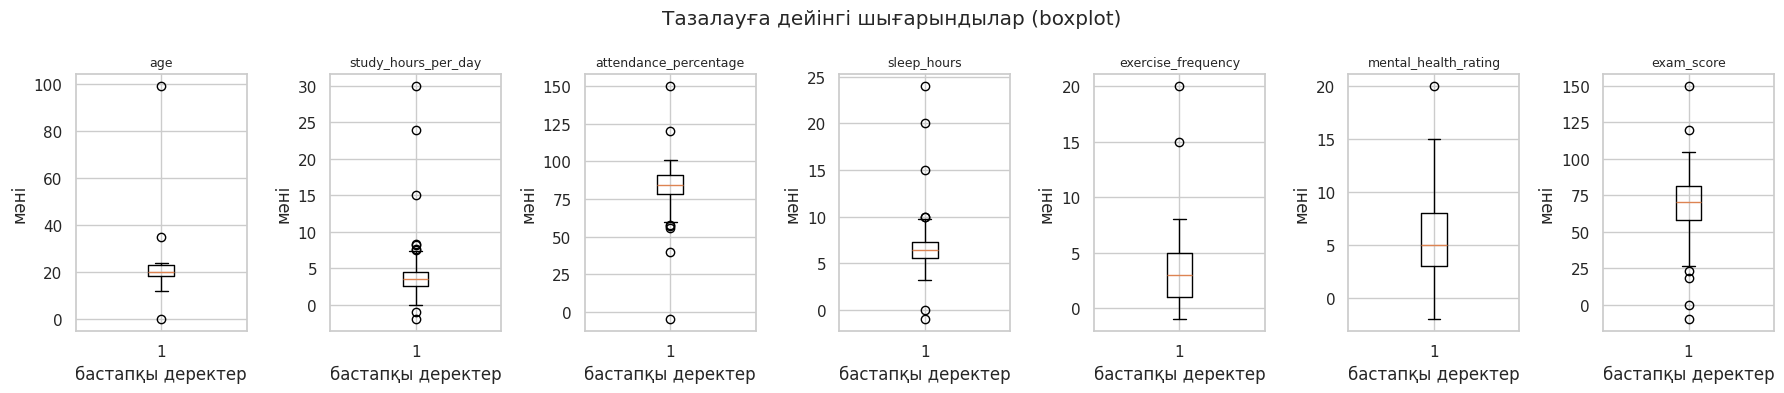

In [9]:
num_show = ['age', 'study_hours_per_day', 'attendance_percentage', 'sleep_hours',
            'exercise_frequency', 'mental_health_rating', 'exam_score']
fig, axes = plt.subplots(1, len(num_show), figsize=(18, 4))
for ax, col in zip(axes, num_show):
    ax.boxplot(df_raw[col].dropna())
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('бастапқы деректер')
    ax.set_ylabel('мәні')
fig.suptitle('Тазалауға дейінгі шығарындылар (boxplot)')
plt.tight_layout(); plt.show()

In [10]:
# Мақсатты көрсеткіштің ең кіші мәндері: 0 балл басқалардан қаншалықты алыс?
print(np.sort(df_raw['exam_score'].dropna().unique())[:8])
df_raw[df_raw['exam_score'] <= 0]

[-10.    0.   18.4  23.1  26.7  26.8  27.6  28. ]


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
148,S1280,20.0,Female,4.5,4.6,2.0,No,87.9,6.5,Fair,2,Bachelor,Good,6,No,-10.0
295,S1196,18.0,Male,2.7,2.1,1.9,No,88.9,8.7,Good,4,High School,Poor,5,No,0.0


**Деректер сапасы бойынша анықталған мәселелер:**

| Мәселе | Көлемі | Не істейміз |
|---|---|---|
| Бос мәндер | 9 бағанда; ең көбі `parental_education_level` — 94 (9.2%), қалғандары ~1% | Pipeline ішінде толтыру (тек train бойынша) |
| Толық қайталанатын жолдар | 20 | Жою |
| Бірдей `student_id`, бірақ әртүрлі деректер | 8 жұп | Сақтау (әртүрлі студенттер), ID модельге кірмейді |
| Категориялардың әртүрлі жазылуы (`' female '`, `'MALE'`, `'NO '`, `' GOOD'`) | 5 бағанда, 74 мән | Біріздендіру |
| Логикаға қайшы сандық мәндер (жас 0/99, ұйқы 24 сағат, қатысу 150%, рейтинг 20) | 31 мән 9 бағанда | `NaN`-ға ауыстыру → толтыру |
| `exam_score` қате (−10, 105, 120, 150) немесе жоқ | 4 + 9 | Жолды жою |
| `exam_score = 0` | 1 | Аномалия ретінде жою |

Маңызды байқау: қате мәндердің саны аз (әр бағанда 4–5), бірақ олар өте экстремалды (мысалы, 30 сағат оқу). Linear Regression сияқты модельдер мұндай нүктелерге өте сезімтал — бір ғана «30 сағат» коэффициентті айтарлықтай бұрып жібереді. Сондықтан оларды тазалау міндетті.

`exam_score = 0` формалды түрде [0, 100] аралығында, бірақ ол **оқшау**: келесі ең кіші баға — 18.4, ал бұл студенттің әдеттері мүлдем қалыпты. Бұл енгізу қатесі немесе емтиханға келмеу (білім деңгейінің көрсеткіші емес).

## 4. Деректерді тазалау

**Қабылданған шешімдер және негіздемесі:**

1. **Толық көшірмелерді жою.** Бірдей жолдар бір студенттің екі рет енгізілгенін білдіреді; оларды қалдырсақ, модель кейбір студенттерге көбірек «салмақ» береді, ал train/test бөлгенде бір жазба екі жаққа да түсіп, бағалауды жасанды түрде жақсартады (data leakage).
2. **Бірдей `student_id`, бірақ әртүрлі мәндер** — бұлар әртүрлі адамдар (жасы, жынысы, бағасы басқа), ID жай қайталанған. Сондықтан оларды жоймаймыз. `student_id` модельге кірмейді — оның болжамдық мағынасы жоқ.
3. **Категориялық мәндерді біріздендіру:** бос орындарды алып тастау және бірдей регистрге келтіру (`' female '` → `Female`, `'NO '` → `No`). Әйтпесе бір категория бірнеше бөлек категория болып саналады.
4. **Мүмкін емес мәндерді `NaN`-ға ауыстыру.** Мысалы, қатысу 150% немесе ұйқы 24 сағат — бұл енгізу қателері. Оларды жою орнына бос мән деп белгілейміз, ал кейін басқа белгілердегі пайдалы ақпарат сақталады, бос мән Pipeline ішінде толтырылады.
5. **Мақсатты көрсеткіш (`exam_score`) бос немесе қате жолдарды жою.** Мақсатты мәнді «ойдан толтыру» модельді қате нәрсеге үйретеді, сондықтан ондай жолдар оқытуға жарамсыз. Сонымен қатар `exam_score = 0` болатын бір жазба жойылады: бұл студенттің әдеттері қалыпты (күніне 2.7 сағат оқиды, қатысуы 89%), ал келесі ең төмен баға 18.4 — яғни 0 балл не енгізу қатесі, не студент емтиханға келмеген. Екі жағдайда да бұл әдеттер мен білім арасындағы байланысты көрсетпейді.
6. **Бос мәндерді толтыру** осы жерде емес, кейін **тек оқыту таңдамасы бойынша** (Pipeline ішінде) жасалады — тест деректерінің статистикасы модельге «ағып кетпеуі» үшін.

In [11]:
df = df_raw.copy()
n0 = len(df)

# 1) толық көшірмелер
df = df.drop_duplicates()
print(f'Көшірмелер жойылды: {n0 - len(df)}')

# 3) категорияларды біріздендіру
for c in cat_cols:
    df[c] = df[c].str.strip().str.title()
print({c: sorted(df[c].dropna().unique()) for c in cat_cols})

# 4) мүмкін емес мәндер -> NaN
n_bad = 0
for col, (lo, hi) in valid_ranges.items():
    mask = (df[col] < lo) | (df[col] > hi)
    n_bad += mask.sum()
    df.loc[mask, col] = np.nan
print(f'NaN-ға ауыстырылған қате мәндер: {n_bad}')

# 5) мақсаты жоқ жолдар
before = len(df)
df = df.dropna(subset=['exam_score']).reset_index(drop=True)
print(f'exam_score жоқ жолдар жойылды: {before - len(df)}')

# 6) exam_score = 0 — аномалия (келесі ең кіші мән 18.4), әдеттері қалыпты студент
before = len(df)
df = df[df['exam_score'] > 0].reset_index(drop=True)
print(f'exam_score = 0 аномалиясы жойылды: {before - len(df)}')
print('Тазаланған деректер өлшемі:', df.shape)

Көшірмелер жойылды: 20
{'gender': ['Female', 'Male', 'Other'], 'part_time_job': ['No', 'Yes'], 'diet_quality': ['Fair', 'Good', 'Poor'], 'parental_education_level': ['Bachelor', 'High School', 'Master'], 'internet_quality': ['Average', 'Good', 'Poor'], 'extracurricular_participation': ['No', 'Yes']}
NaN-ға ауыстырылған қате мәндер: 31
exam_score жоқ жолдар жойылды: 13
exam_score = 0 аномалиясы жойылды: 1
Тазаланған деректер өлшемі: (986, 16)


In [12]:
df.isna().sum()[df.isna().sum() > 0]

,0
age,16
gender,10
study_hours_per_day,18
attendance_percentage,16
sleep_hours,15
diet_quality,10
exercise_frequency,4
parental_education_level,91
internet_quality,8
mental_health_rating,5


## 5. Барлаушы талдау (EDA)

### 5.1 Мақсатты көрсеткіштің таралуы

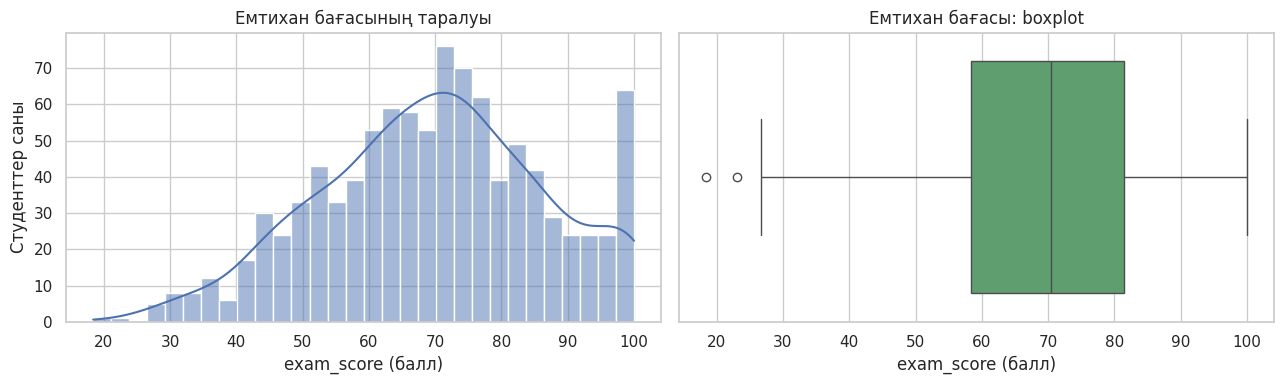

count    986.00
mean      69.61
std       16.86
min       18.40
25%       58.42
50%       70.50
75%       81.47
max      100.00
Name: exam_score, dtype: float64
100 балл алғандар: 46


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['exam_score'], bins=30, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Емтихан бағасының таралуы')
axes[0].set_xlabel('exam_score (балл)'); axes[0].set_ylabel('Студенттер саны')
sns.boxplot(x=df['exam_score'], ax=axes[1], color='#55A868')
axes[1].set_title('Емтихан бағасы: boxplot')
axes[1].set_xlabel('exam_score (балл)')
plt.tight_layout(); plt.show()
print(df['exam_score'].describe().round(2))
print('100 балл алғандар:', (df['exam_score'] == 100).sum())

**Мақсатты көрсеткіш туралы:**
- Тазалаудан кейін орташа баға **69.6**, медиана **70.5**, стандартты ауытқу **16.9** балл, ауқымы 18.4–100.
- Таралуы қалыпты таралуға жақын, сәл солға қисайған.
- **46 студент (≈4.7%) дәл 100 балл алған** — бұл «төбе әсері» (ceiling effect): шкала 100-де қиылған, сондықтан шын мәнінде «100-ден жоғары» деңгейдегі студенттер бір мәнге жиналған. Бұл модельдер үшін маңызды: жоғары бағалы студенттерде сызықтық модель 100-ден асатын мән болжауы мүмкін, сондықтан кейін болжамды [0, 100] аралығына шектейміз.
- Стандартты ауытқу 16.9 болғандықтан, «әрқашан орташаны болжайтын» модель шамамен 17 балл RMSE береді — біздің модельдер осы деңгейден айтарлықтай жақсы болуы тиіс.

### 5.2 Сандық белгілер мен бағаның корреляциясы

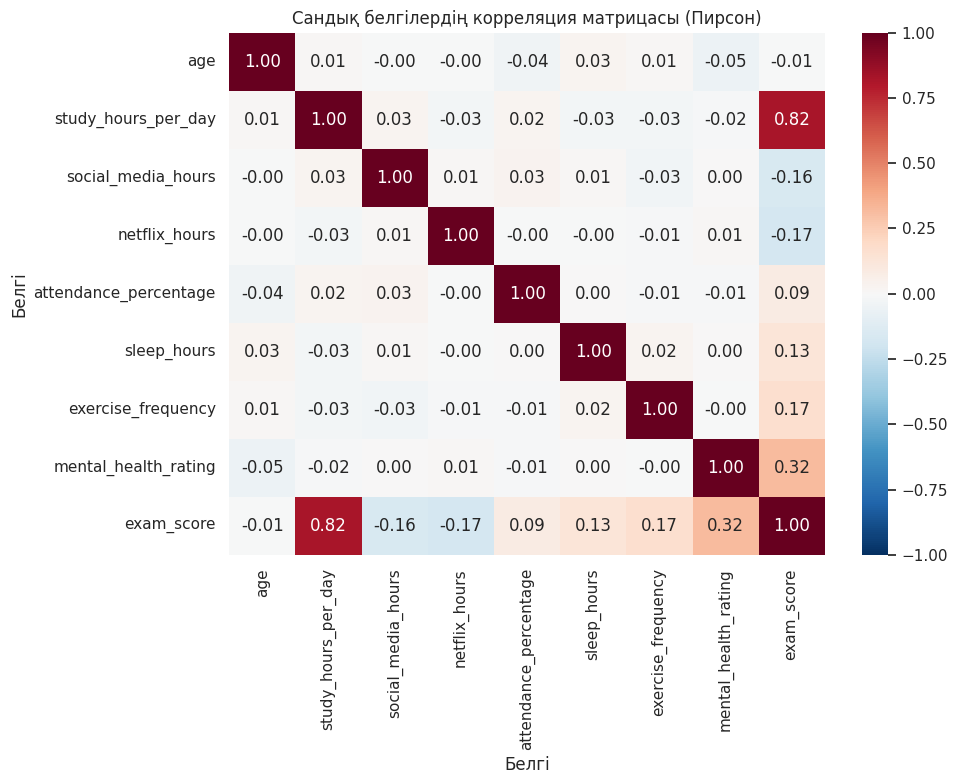

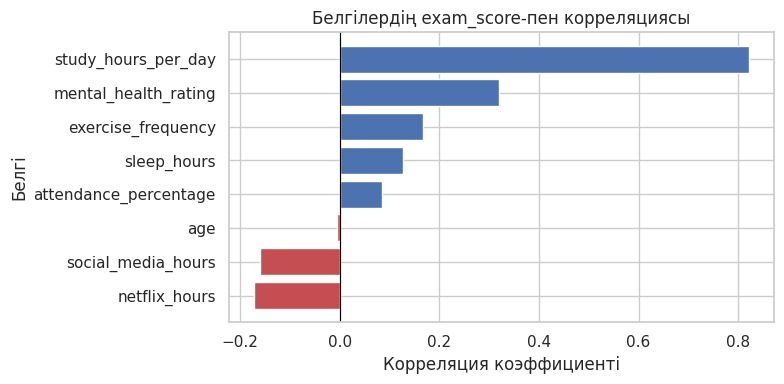

,exam_score
netflix_hours,-0.173
social_media_hours,-0.160
age,-0.005
attendance_percentage,0.085
sleep_hours,0.127
exercise_frequency,0.166
mental_health_rating,0.320
study_hours_per_day,0.822


In [14]:
num_cols = ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
            'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']
corr = df[num_cols + ['exam_score']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Сандық белгілердің корреляция матрицасы (Пирсон)')
plt.xlabel('Белгі'); plt.ylabel('Белгі')
plt.tight_layout(); plt.show()

target_corr = corr['exam_score'].drop('exam_score').sort_values()
plt.figure(figsize=(8, 4))
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in target_corr]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.title('Белгілердің exam_score-пен корреляциясы')
plt.xlabel('Корреляция коэффициенті'); plt.ylabel('Белгі')
plt.axvline(0, color='black', lw=0.8)
plt.tight_layout(); plt.show()
target_corr.round(3)

**Корреляция нәтижесі:**
- **`study_hours_per_day` — өте күшті оң байланыс (r ≈ 0.82).** Бұл басқа белгілерден әлдеқайда күшті.
- **`mental_health_rating` — орташа оң байланыс (r ≈ 0.32).**
- `exercise_frequency` (0.17) және `sleep_hours` (0.13) — әлсіз оң байланыс.
- `netflix_hours` (−0.17) және `social_media_hours` (−0.16) — әлсіз **теріс** байланыс.
- `attendance_percentage` (0.09) күтпегендей әлсіз, ал `age` (≈0) іс жүзінде байланыссыз.
- Белгілердің өзара корреляциясы өте төмен (|r| < 0.1) — яғни мультиколлинеарлық проблемасы жоқ, әр белгі өз ақпаратын береді. Бұл Linear Regression коэффициенттерін сенімді интерпретациялауға мүмкіндік береді.

*Ескерту:* Пирсон корреляциясы тек сызықтық байланысты өлшейді, сондықтан келесі қадамда шашырау диаграммаларымен сызықтық емес заңдылықтарды тексереміз.

### 5.3 Негізгі тәуелділіктер: шашырау диаграммалары

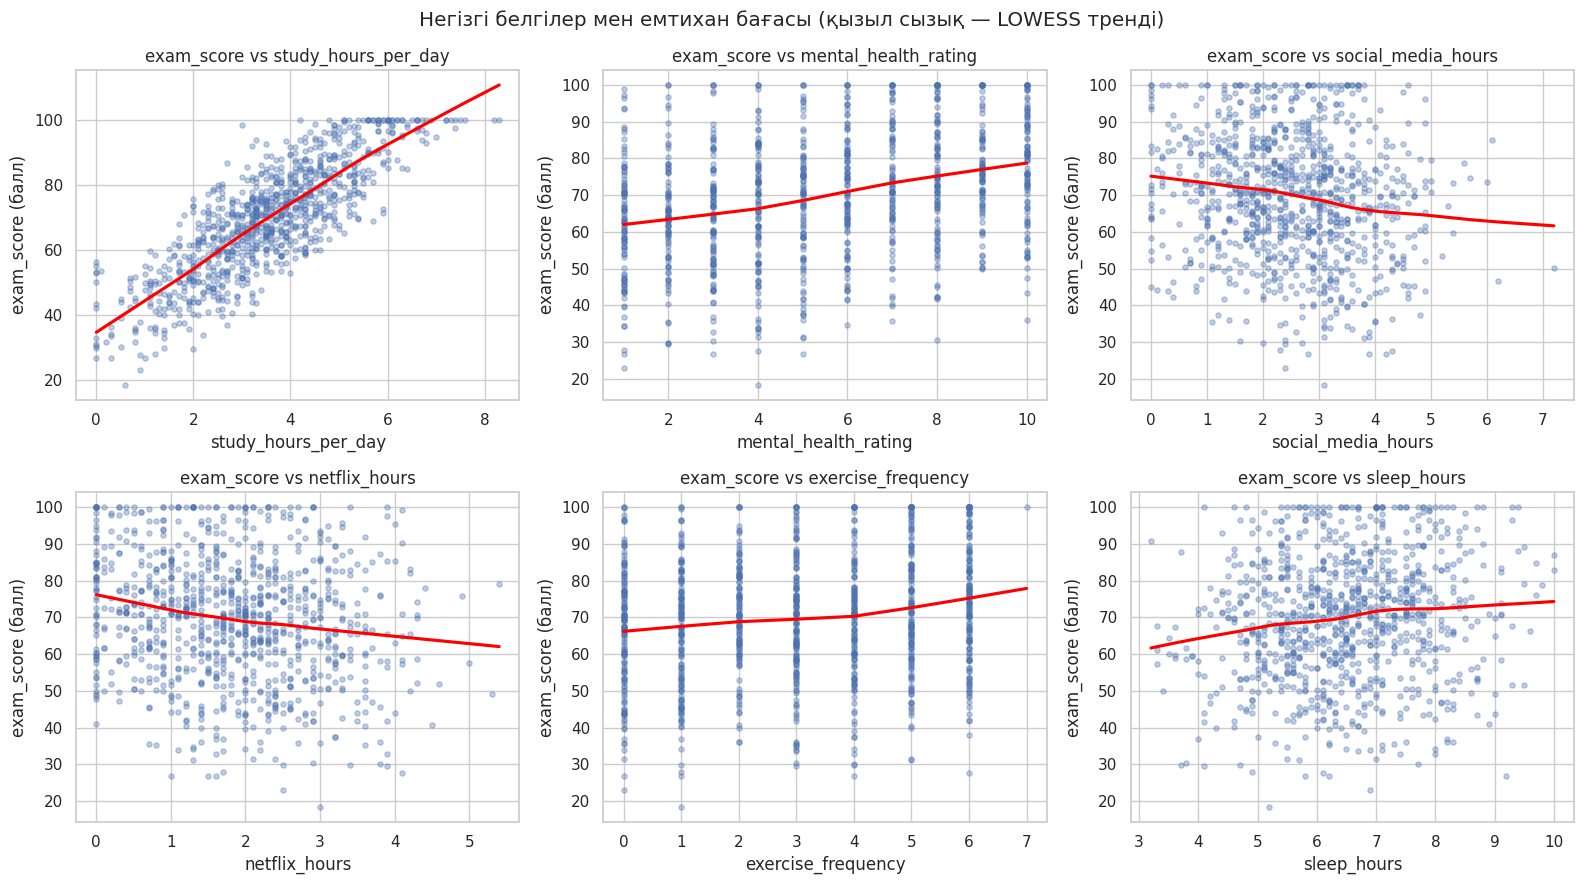

In [15]:
pairs = ['study_hours_per_day', 'mental_health_rating', 'social_media_hours',
         'netflix_hours', 'exercise_frequency', 'sleep_hours']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), pairs):
    sns.regplot(data=df, x=col, y='exam_score', ax=ax, scatter_kws={'alpha': 0.35, 's': 14},
                line_kws={'color': 'red'}, lowess=True)
    ax.set_title(f'exam_score vs {col}')
    ax.set_xlabel(col); ax.set_ylabel('exam_score (балл)')
fig.suptitle('Негізгі белгілер мен емтихан бағасы (қызыл сызық — LOWESS тренді)')
plt.tight_layout(); plt.show()

**Шашырау диаграммаларынан:**
- `study_hours_per_day` пен баға арасындағы байланыс **сызықтық** дерлік: LOWESS қисығы түзу сызыққа өте жақын. Тек ең жоғарғы бөлікте (6+ сағат) 100 баллдағы «төбеге» тіреледі.
- `mental_health_rating` — біркелкі өсетін тренд, нүктелердің шашырауы үлкен (себебі бағаны негізінен оқу уақыты анықтайды).
- `social_media_hours` және `netflix_hours` — жайлап төмендейтін тренд.
- `exercise_frequency` және `sleep_hours` — әлсіз оң тренд.
- Ешбір белгіде U-тәрізді немесе күрделі сызықтық емес пішін байқалмады. **Бұл маңызды гипотеза береді: сызықтық модель бұл деректерде жақсы жұмыс істеуі мүмкін**, ал ағаш модельдерінің артықшылығы (сызықтық еместікті ұстау) мұнда аз пайда береді.

### 5.4 Зерттеу сұрағы 1: оқу уақыты мен баға — топтар бойынша

,count,mean,median
study_group,,,
0–1,43,40.4,42.0
1–2,106,49.5,49.8
2–3,199,60.4,60.6
3–4,269,70.1,70.7
4–5,206,79.0,78.6
5–6,105,88.1,89.3
6+,40,97.5,100.0


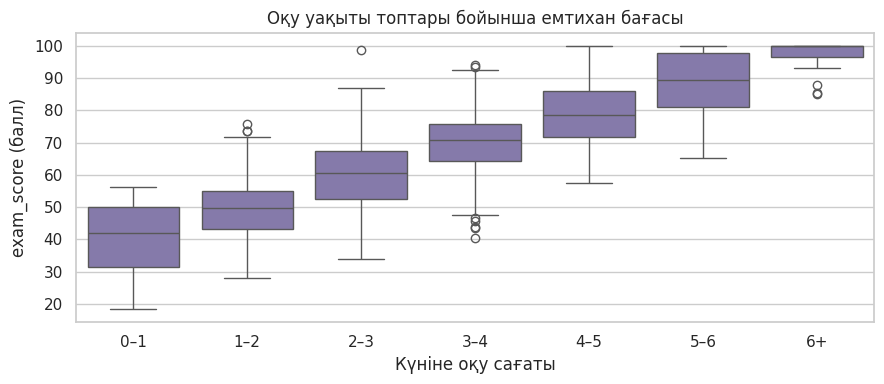

In [16]:
df['study_group'] = pd.cut(df['study_hours_per_day'], bins=[-0.1, 1, 2, 3, 4, 5, 6, 12],
                           labels=['0–1', '1–2', '2–3', '3–4', '4–5', '5–6', '6+'])
g = df.groupby('study_group', observed=True)['exam_score'].agg(['count', 'mean', 'median']).round(1)
display(g)
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x='study_group', y='exam_score', color='#8172B2')
plt.title('Оқу уақыты топтары бойынша емтихан бағасы')
plt.xlabel('Күніне оқу сағаты'); plt.ylabel('exam_score (балл)')
plt.tight_layout(); plt.show()

**Жауап (1-сұрақ):** оқу уақыты мен баға арасында **айқын, біркелкі өсетін** байланыс бар. Әр қосымша сағат тобы орташа бағаны шамамен **+9–10 баллға** көтереді: 0–1 сағат оқитындардың орташасы **40.4**, ал 6+ сағат оқитындардікі **97.5** (медианасы 100). Өсу қарқыны барлық топта шамамен бірдей — бұл байланыстың сызықтық екенін растайды. Жоғарғы топта 100 баллдық шекараға жеткендіктен өсу «тоқтайды».

### 5.5 Зерттеу сұрағы 2: экран уақыты

Экран уақыты мен бағаның корреляциясы: -0.233


,count,mean
screen_group,,
Q1 (аз),258,75.6
Q2,260,69.3
Q3,232,67.1
Q4 (көп),236,65.9


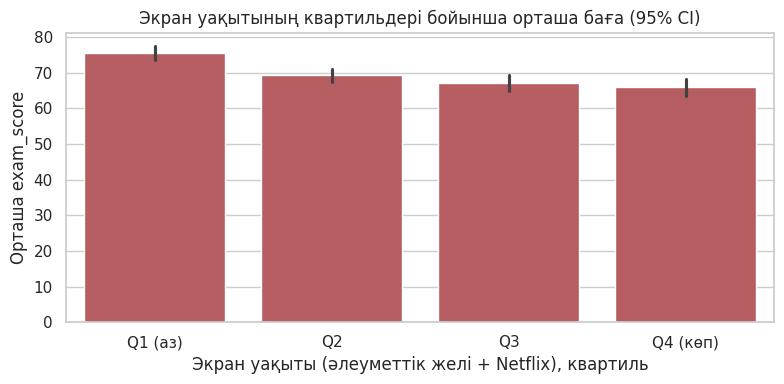

In [17]:
df['screen_time'] = df['social_media_hours'] + df['netflix_hours']
print('Экран уақыты мен бағаның корреляциясы:', round(df[['screen_time', 'exam_score']].corr().iloc[0, 1], 3))
df['screen_group'] = pd.qcut(df['screen_time'], 4, labels=['Q1 (аз)', 'Q2', 'Q3', 'Q4 (көп)'])
display(df.groupby('screen_group', observed=True)['exam_score'].agg(['count', 'mean']).round(1))

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x='screen_group', y='exam_score', color='#C44E52', errorbar=('ci', 95))
plt.title('Экран уақытының квартильдері бойынша орташа баға (95% CI)')
plt.xlabel('Экран уақыты (әлеуметтік желі + Netflix), квартиль'); plt.ylabel('Орташа exam_score')
plt.tight_layout(); plt.show()

**Жауап (2-сұрақ):** иә, экран уақыты бағамен **теріс** байланысты (r ≈ −0.23 — әлеуметтік желі мен Netflix-ті жеке алғаннан күштірек). Экран уақыты ең аз ширектегі студенттердің орташа бағасы **75.6**, ең көп ширектегілердікі — **65.9**, яғни шамамен **10 балл** айырма; сенімділік аралықтары қиылыспайды. Бірақ әсер оқу уақытының әсерінен әлдеқайда әлсіз.

### 5.6 Зерттеу сұрақтары 3–4: категориялық белгілер

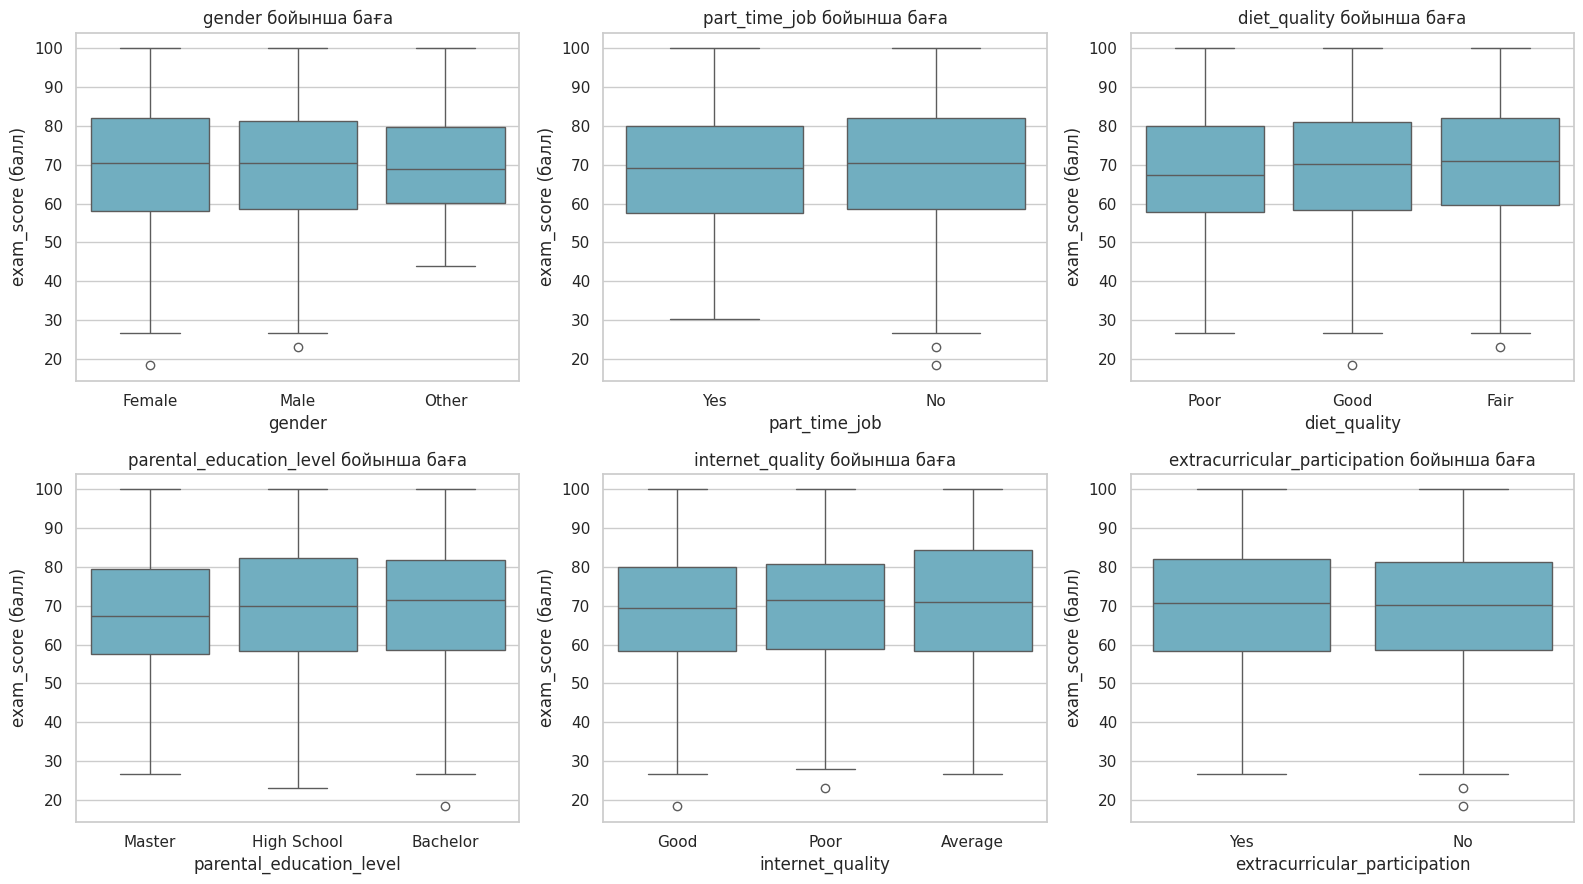

,белгі,топтар арасындағы ең үлкен айырма (балл),топтардың орташасы
3,parental_education_level,2.13,"{'Bachelor': 70.2, 'High School': 69.7, 'Maste..."
2,diet_quality,2.09,"{'Fair': 70.4, 'Good': 69.2, 'Poor': 68.3}"
4,internet_quality,1.85,"{'Average': 70.5, 'Good': 68.7, 'Poor': 69.8}"
1,part_time_job,1.08,"{'No': 69.8, 'Yes': 68.8}"
0,gender,1.03,"{'Female': 69.6, 'Male': 69.6, 'Other': 70.6}"
5,extracurricular_participation,0.02,"{'No': 69.6, 'Yes': 69.6}"


In [18]:
cat_plot = ['gender', 'part_time_job', 'diet_quality', 'parental_education_level',
            'internet_quality', 'extracurricular_participation']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    order = df.groupby(col)['exam_score'].mean().sort_values().index
    sns.boxplot(data=df, x=col, y='exam_score', order=order, ax=ax, color='#64B5CD')
    ax.set_title(f'{col} бойынша баға')
    ax.set_xlabel(col); ax.set_ylabel('exam_score (балл)')
plt.tight_layout(); plt.show()

summary = []
for col in cat_plot:
    m = df.groupby(col)['exam_score'].mean()
    summary.append({'белгі': col, 'топтар арасындағы ең үлкен айырма (балл)': round(m.max() - m.min(), 2),
                    'топтардың орташасы': m.round(1).to_dict()})
pd.DataFrame(summary).sort_values('топтар арасындағы ең үлкен айырма (балл)', ascending=False)

**Жауап (3–4-сұрақтар, категориялық бөлігі):** барлық категориялық белгілер бойынша топтардың орташа бағасы бір-бірінен **ең көбі ~2 баллға** ғана ерекшеленеді (ата-ана білімі — 2.1, тамақтану — 2.1, интернет — 1.9, жұмыс — 1.1, жыныс — 1.0, үйірмелер — 0.0). Бағаның стандартты ауытқуы 17 балл болғанда, бұл айырмалар **кездейсоқ шу деңгейінде**. Boxplot-тарда да таралулар іс жүзінде бірдей.

Қызықты нәтиже: ата-ананың білімі, интернет сапасы, жартылай жұмыс — интуиция бойынша маңызды көрінетін факторлар — бұл деректерде бағаны түсіндірмейді. Ал жеке әдеттер (оқу уақыты, психикалық жағдай, экран уақыты, спорт, ұйқы) — түсіндіреді. Яғни баға **студенттің өзі өзгерте алатын** факторларға көбірек байланысты.

In [19]:
df = df.drop(columns=['study_group', 'screen_group', 'screen_time'])  # тек талдауға арналған уақытша бағандар

## 6. Деректерді модельге дайындау

**Белгілерді таңдау.** `student_id` алынып тасталады (идентификатор, болжамдық мағынасы жоқ). Қалған барлық 14 белгі қалдырылады: EDA кейбір белгілердің (жас, жыныс) әлсіз екенін көрсетті, бірақ ағаш модельдері мен регуляризациясыз Linear Regression үшін оларды қалдыру — модельдің өзі олардың маңызын «шешуі» үшін. Олардың шын үлесін 10-бөлімде permutation importance арқылы тексереміз.

**Түрлендірулер (ColumnTransformer + Pipeline):**
- *Сандық белгілер:* бос мәндер **медианамен** толтырылады (медиана шығарындыларға тұрақты), содан кейін `StandardScaler` (Linear Regression коэффициенттерін салыстыру үшін; ағаштарға әсер етпейді).
- *Реттік белгілер* (`diet_quality`, `internet_quality`, `parental_education_level`): табиғи реті бар (Poor < Fair < Good), сондықтан `OrdinalEncoder`. `parental_education_level`-тің 9%-ы бос — бұл «белгісіз» деген ақпарат болуы мүмкін, сондықтан алдымен ең жиі мәнмен толтырамыз.
- *Номиналды белгілер* (`gender`, `part_time_job`, `extracurricular_participation`): реті жоқ, сондықтан `OneHotEncoder` (бір категорияны тастаймыз — мультиколлинеарлықты болдырмау үшін).

**Бөлу:** 80% оқыту / 20% тест, `random_state=42`. Барлық толтыру/масштабтау параметрлері **тек оқыту таңдамасында** `fit` жасалады, тест таңдамасы тек соңғы бағалауда қолданылады.

In [20]:
TARGET = 'exam_score'
X = df.drop(columns=[TARGET, 'student_id'])
y = df[TARGET]

numeric_features = ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
                    'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']
ordinal_features = ['diet_quality', 'internet_quality', 'parental_education_level']
ordinal_categories = [['Poor', 'Fair', 'Good'],
                      ['Poor', 'Average', 'Good'],
                      ['High School', 'Bachelor', 'Master']]
nominal_features = ['gender', 'part_time_job', 'extracurricular_participation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Оқыту:', X_train.shape, ' Тест:', X_test.shape)
print(f'y_train орташасы = {y_train.mean():.2f}, y_test орташасы = {y_test.mean():.2f}')

Оқыту: (788, 14)  Тест: (198, 14)
y_train орташасы = 69.72, y_test орташасы = 69.16


In [21]:
def make_preprocessor():
    num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale', StandardScaler())])
    ord_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                         ('encode', OrdinalEncoder(categories=ordinal_categories))])
    nom_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                         ('encode', OneHotEncoder(drop='first', handle_unknown='ignore'))])
    return ColumnTransformer([('num', num_pipe, numeric_features),
                              ('ord', ord_pipe, ordinal_features),
                              ('nom', nom_pipe, nominal_features)])

prep = make_preprocessor().fit(X_train)
feature_names = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
print('Модельге кіретін белгілер саны:', len(feature_names))
print(feature_names)

Модельге кіретін белгілер саны: 15
['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating', 'diet_quality', 'internet_quality', 'parental_education_level', 'gender_Male', 'gender_Other', 'part_time_job_Yes', 'extracurricular_participation_Yes']


## 7. Модельдерді құру

| Модель | Неліктен салыстыруға енгізілді |
|---|---|
| **Linear Regression** | Базалық модель (эталон). Қарапайым, интерпретацияланатын; EDA көрсеткендей негізгі байланыстар сызыққа жақын болса, ол жақсы нәтиже беруі мүмкін. |
| **Decision Tree Regressor** | Сызықтық емес тәуелділіктер мен белгілердің өзара әсерін ұстай алады. Бірақ жеке ағаш шамадан тыс оқуға (overfitting) бейім. |
| **Random Forest Regressor** | Көп ағаштың орташасы — дисперсияны азайтады, бір ағаштан тұрақтырақ. |
| **Gradient Boosting Regressor** | Ағаштарды бірінен соң бірі қателерді түзететіндей құрады; кестелік деректерде жиі ең мықты әдістердің бірі. |

Барлық модельдер **бірдей белгілер жиынымен** (14 бастапқы белгі → 15 түрлендірілген баған) оқытылады — сонда салыстыру әділ болады.

**Болжамды шектеу.** Емтихан бағасы 0–100 шкаласында, ал 5.4-бөлімде 6+ сағат оқитындардың медианасы 100 балл екенін көрдік (46 студент 100 алған — «төбе әсері»). Сызықтық модель шкаладан тыс мән (мысалы, 113) бере алады, сондықтан әр модель `ClipRegressor`-ға оралып, болжам [0, 100] аралығына қиылады.

**Гиперпараметрлер.** Ағаш модельдері үшін оқыту таңдамасында 5-fold кросс-валидациямен `GridSearchCV` жүргіземіз (тест таңдамасы қолданылмайды).

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def pipe(model):
    return Pipeline([('prep', make_preprocessor()), ('model', ClipRegressor(model))])

search_spaces = {
    'Linear Regression': (pipe(LinearRegression()), {}),
    'Decision Tree': (pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                      {'model__estimator__max_depth': [3, 4, 5, 6, 8, None],
                       'model__estimator__min_samples_leaf': [1, 5, 10, 20]}),
    'Random Forest': (pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
                      {'model__estimator__n_estimators': [300],
                       'model__estimator__max_depth': [None, 10],
                       'model__estimator__min_samples_leaf': [1, 3, 5],
                       'model__estimator__max_features': [0.5, 1.0]}),
    'Gradient Boosting': (pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
                          {'model__estimator__n_estimators': [200, 400],
                           'model__estimator__learning_rate': [0.03, 0.05, 0.1],
                           'model__estimator__max_depth': [2, 3],
                           'model__estimator__subsample': [0.8, 1.0]}),
}

best_models, cv_rows = {}, []
for name, (p, grid) in search_spaces.items():
    gs = GridSearchCV(p, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    res = cross_validate(gs.best_estimator_, X_train, y_train, cv=cv,
                         scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'],
                         return_train_score=True)
    cv_rows.append({'Модель': name,
                    'CV MAE': -res['test_neg_mean_absolute_error'].mean(),
                    'CV RMSE': -res['test_neg_root_mean_squared_error'].mean(),
                    'CV RMSE std': res['test_neg_root_mean_squared_error'].std(),
                    'CV R²': res['test_r2'].mean(),
                    'Train R²': res['train_r2'].mean(),
                    'Үздік параметрлер': {k.replace('model__estimator__', ''): v for k, v in gs.best_params_.items()}})
cv_table = pd.DataFrame(cv_rows).set_index('Модель')
cv_table.round(3)

,CV MAE,CV RMSE,CV RMSE std,CV R²,Train R²,Үздік параметрлер
Модель,,,,,,
Linear Regression,4.204,5.395,0.389,0.896,0.902,{}
Decision Tree,6.720,8.558,0.338,0.739,0.827,"{'max_depth': 8, 'min_samples_leaf': 20}"
Random Forest,5.314,6.616,0.218,0.844,0.979,"{'max_depth': None, 'max_features': 0.5, 'min_..."
Gradient Boosting,4.470,5.708,0.281,0.883,0.942,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."


**Кросс-валидация нәтижесі (тек оқыту таңдамасында, 5-fold):**
- **Linear Regression** ең кіші CV RMSE береді (**≈5.40**, R² ≈ 0.90), және оның Train R² (0.90) мен CV R² бірдей — overfitting жоқ.
- **Gradient Boosting** өте жақын (CV RMSE ≈ 5.71). GridSearch таңдаған параметрлер (`max_depth=2`, яғни өте таяз ағаштар) — модельдің өзі қарапайым, аддитивті құрылымды «қалайтынын» көрсетеді.
- **Random Forest**: Train R² ≈ 0.98, бірақ CV R² ≈ 0.84 — айқын **overfitting**: оқыту деректерін жаттап алады.
- **Decision Tree** — ең әлсіз (CV RMSE ≈ 8.56): бір ағаш үздіксіз сызықтық байланысты «баспалдақтармен» ғана жуықтай алады.

## 8. Модельдерді бағалау және салыстыру

**Метрикаларды таңдау:**
- **MAE** (орташа абсолюттік қате) — «модель орта есеппен неше баллға қателеседі» деген түсінікті шама; оқытушыға түсіндіру оңай.
- **RMSE** — үлкен қателерді қаттырақ айыптайды. Бізге студенттің бағасын 25 баллға қате болжау (мысалы, «қауіпсіз» деп құлайтын студентті жіберіп алу) әсіресе қауіпті, сондықтан RMSE маңызды.
- **R²** — модель баға дисперсиясының қандай үлесін түсіндіретінін көрсетеді; модельдерді деректердің масштабынан тәуелсіз салыстыруға мүмкіндік береді.
- Қосымша: Train R² мен Test R² айырмасы — **overfitting** белгісі.
- Салыстыру нүктесі ретінде **baseline** — барлық студентке оқыту таңдамасының орташа бағасын беретін «модель».

*Ескерту:* бұл регрессия есебі, сондықтан қателер матрицасы мен класс ықтималдығы қолданылмайды; оның орнына қалдықтарды талдау (9-бөлім) және болжамның шашырауы (11-бөлім) көрсетіледі.

In [23]:
rows = []
test_preds = {}
for name, m in best_models.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    test_preds[name] = p_te
    rows.append({'Модель': name,
                 'Train MAE': mean_absolute_error(y_train, p_tr),
                 'Test MAE': mean_absolute_error(y_test, p_te),
                 'Train RMSE': mean_squared_error(y_train, p_tr) ** 0.5,
                 'Test RMSE': mean_squared_error(y_test, p_te) ** 0.5,
                 'Train R²': r2_score(y_train, p_tr),
                 'Test R²': r2_score(y_test, p_te),
                 'CV RMSE (5-fold)': cv_table.loc[name, 'CV RMSE']})
results = pd.DataFrame(rows).set_index('Модель')
results['R² айырмасы (train−test)'] = results['Train R²'] - results['Test R²']
results = results.sort_values('Test RMSE')
display(results.round(3))

# baseline: әрқашан орташа бағаны болжау
base = np.full(len(y_test), y_train.mean())
print(f'Baseline (тек орташа): MAE={mean_absolute_error(y_test, base):.2f}, '
      f'RMSE={mean_squared_error(y_test, base) ** 0.5:.2f}, R²={r2_score(y_test, base):.3f}')

,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²,CV RMSE (5-fold),R² айырмасы (train−test)
Модель,,,,,,,,
Linear Regression,4.109,4.474,5.295,5.753,0.901,0.883,5.395,0.018
Gradient Boosting,3.290,4.964,4.233,6.385,0.937,0.856,5.708,0.081
Random Forest,1.932,5.598,2.410,7.203,0.980,0.817,6.616,0.163
Decision Tree,5.521,7.245,6.962,9.183,0.829,0.703,8.558,0.127


Baseline (тек орташа): MAE=13.21, RMSE=16.85, R²=-0.001


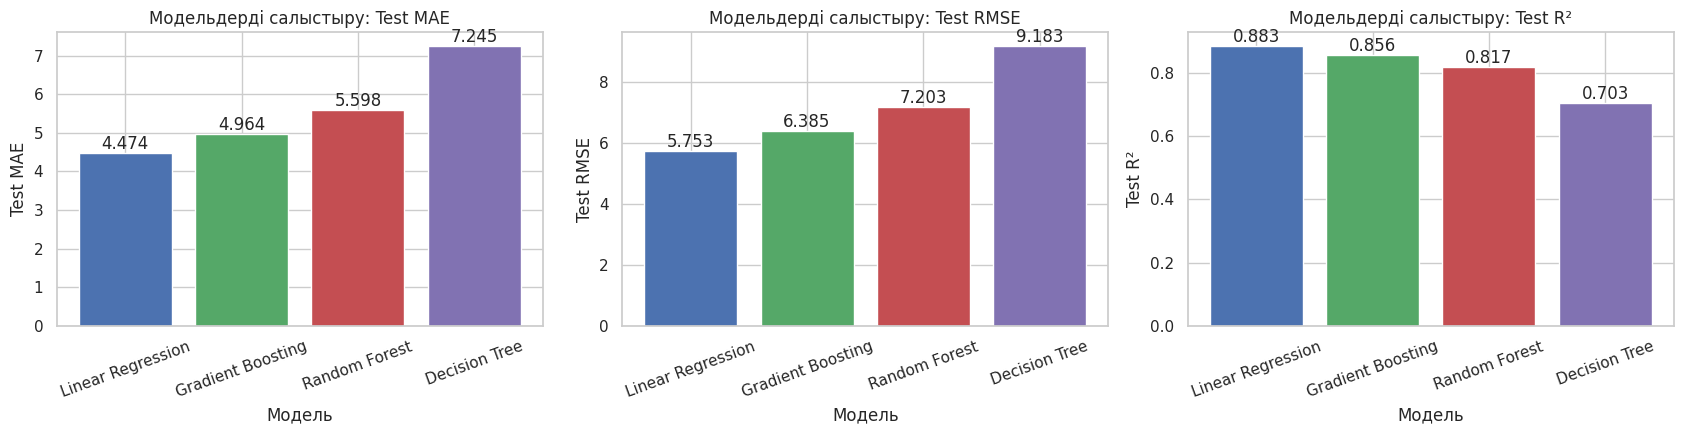

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ['Test MAE', 'Test RMSE', 'Test R²']):
    vals = results[metric]
    ax.bar(vals.index, vals.values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
    ax.set_title(f'Модельдерді салыстыру: {metric}')
    ax.set_xlabel('Модель'); ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=20)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

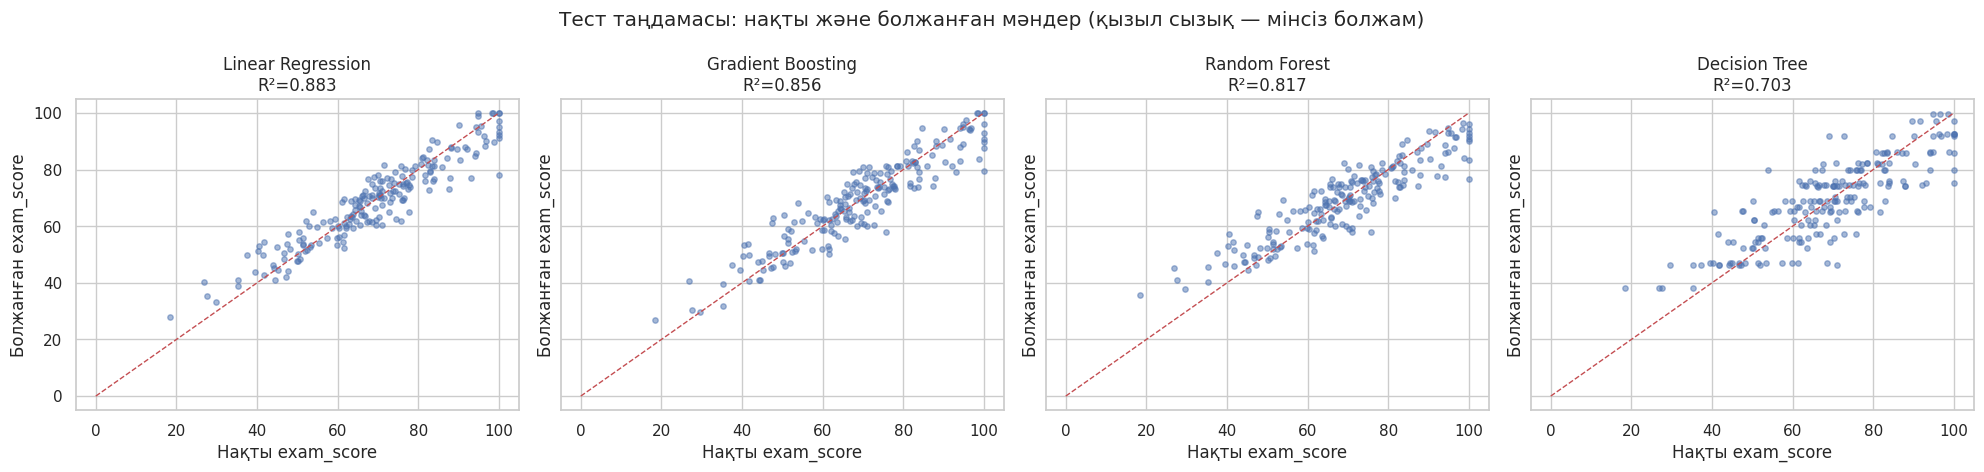

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for ax, name in zip(axes, results.index):
    ax.scatter(y_test, test_preds[name], alpha=0.5, s=15)
    ax.plot([0, 100], [0, 100], 'r--', lw=1)
    ax.set_title(f'{name}\nR²={r2_score(y_test, test_preds[name]):.3f}')
    ax.set_xlabel('Нақты exam_score'); ax.set_ylabel('Болжанған exam_score')
fig.suptitle('Тест таңдамасы: нақты және болжанған мәндер (қызыл сызық — мінсіз болжам)')
plt.tight_layout(); plt.show()

**Модельдерді салыстыру қорытындысы:**

| | Test MAE | Test RMSE | Test R² | Train−Test R² |
|---|---|---|---|---|
| Baseline (орташа) | 13.21 | 16.85 | 0.00 | — |
| **Linear Regression** | **4.47** | **5.75** | **0.883** | **0.02** |
| Gradient Boosting | 4.96 | 6.39 | 0.856 | 0.08 |
| Random Forest | 5.59 | 7.16 | 0.819 | 0.16 |
| Decision Tree | 7.25 | 9.18 | 0.703 | 0.13 |

**Таңдалған модель — Linear Regression.** Негіздеме тек бір метрикаға сүйенбейді:
1. **Барлық үш метрика бойынша** (MAE, RMSE, R²) тест таңдамасында бірінші орында.
2. **Кросс-валидацияда да** бірінші орында — яғни бұл бір сәтті train/test бөлудің кездейсоқ нәтижесі емес.
3. **Ең тұрақты:** train және test сапасының айырмасы ең аз (0.02), яғни жаңа деректерге жақсы жалпыланады.
4. **Интерпретацияланады:** әр факторның бағаға әсерін баллмен айтуға болады — бұл практикалық есеп үшін (эдвайзерге кеңес беру) өте маңызды.
5. **EDA гипотезасымен сәйкес:** байланыстар сызықтық және аддитивті, белгілер өзара тәуелсіз — бұл дәл Linear Regression-ның болжамдары.

Gradient Boosting жақын нәтиже берді, бірақ күрделірек, интерпретациясы қиынырақ және сапасы бәрібір төмен — оны таңдауға негіз жоқ.

**Мағынасы:** модель студенттің бағасын орта есеппен **±4.5 балл** қателікпен болжайды, бұл baseline-нан (13.2 балл) үш есе жақсы. Модель бағалар айырмашылығының **≈88%-ын** түсіндіреді — қалған 12% деректерде жоқ факторларға (қабілет, алдыңғы білім, емтихан күнгі жағдай) байланысты.

## 9. Қателерді талдау (таңдалған модель)

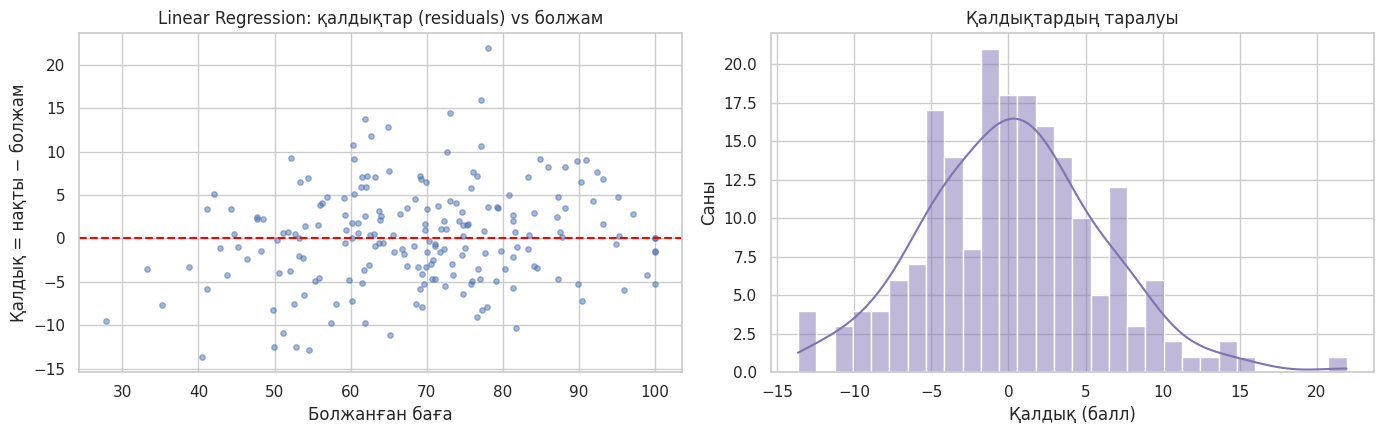

,саны,MAE,орташа_қалдық
score_band,,,
<50 (төмен),26,6.02,-4.90
50–70,74,3.74,-0.70
70–85,65,4.09,1.24
85–100 (жоғары),33,5.67,4.51


In [26]:
BEST = BEST_NAME = 'Linear Regression'
best = best_models[BEST]
err = X_test.copy()
err['actual'] = y_test.values
err['pred'] = best.predict(X_test)
err['residual'] = err['actual'] - err['pred']
err['abs_err'] = err['residual'].abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(err['pred'], err['residual'], alpha=0.5, s=15)
axes[0].axhline(0, color='red', ls='--')
axes[0].set_title(f'{BEST}: қалдықтар (residuals) vs болжам')
axes[0].set_xlabel('Болжанған баға'); axes[0].set_ylabel('Қалдық = нақты − болжам')
sns.histplot(err['residual'], bins=30, kde=True, ax=axes[1], color='#8172B2')
axes[1].set_title('Қалдықтардың таралуы')
axes[1].set_xlabel('Қалдық (балл)'); axes[1].set_ylabel('Саны')
plt.tight_layout(); plt.show()

err['score_band'] = pd.cut(err['actual'], bins=[0, 50, 70, 85, 100.1],
                           labels=['<50 (төмен)', '50–70', '70–85', '85–100 (жоғары)'], right=False)
band = err.groupby('score_band', observed=True).agg(саны=('actual', 'size'),
                                                    MAE=('abs_err', 'mean'),
                                                    орташа_қалдық=('residual', 'mean')).round(2)
display(band)

In [27]:
print('Ең үлкен 8 қате:')
err.sort_values('abs_err', ascending=False).head(8)[
    ['study_hours_per_day', 'mental_health_rating', 'social_media_hours', 'netflix_hours',
     'exercise_frequency', 'attendance_percentage', 'actual', 'pred', 'residual']].round(1)

Ең үлкен 8 қате:


,study_hours_per_day,mental_health_rating,social_media_hours,netflix_hours,exercise_frequency,attendance_percentage,actual,pred,residual
758,NaN,8.0,3.5,2.3,5.0,94.5,100.0,78.1,21.9
209,4.7,10.0,4.1,3.0,3.0,71.2,93.1,77.2,15.9
260,4.4,5.0,3.6,0.3,2.0,76.6,87.5,73.1,14.4
218,2.0,10.0,3.2,3.8,6.0,82.6,75.7,62.0,13.7
72,1.0,1.0,3.9,1.0,4.0,71.0,26.8,40.4,-13.6
361,4.0,1.0,2.3,2.5,6.0,40.0,77.8,65.0,12.8
746,1.9,5.0,3.2,1.2,6.0,75.9,41.7,54.5,-12.8
281,1.7,5.0,1.2,3.2,4.0,76.9,37.4,49.9,-12.5


**Модель қай жерде қателеседі:**
- **Ортаңғы бағаларда (50–85)** модель өте жақсы: MAE ≈ 3.7–4.1 балл.
- **Төмен бағаларда (<50)** MAE ≈ 6.0, ал орташа қалдық теріс (−4.9): модель әлсіз студенттердің бағасын **асыра** болжайды.
- **Жоғары бағаларда (85–100)** MAE ≈ 5.7, қалдық оң (+4.5): модель үздік студенттердің бағасын **төмендетеді**.
- Бұл «орташаға қарай тартылу» (regression to the mean) — модель экстремалды нәтижелерді толық түсіндіре алмайды, себебі ондай студенттердің ерекшелігі деректерде жоқ факторларда жатыр. Жоғары бағаларда оған 100 балдық төбе де әсер етеді.

**Ең үлкен қателердің себептері:**
- **Ең үлкен қате (+21.9)** — `study_hours_per_day` **бос** болған студент (нақты 100, болжам 78). Бос мән медианамен (≈3.5 сағат) толтырылды, ал ең маңызды белгі белгісіз болғанда модель «орташа студентті» болжайды. Яғни ең маңызды белгінің сапасы болжамның сапасын тікелей анықтайды.
- Басқа жағдайлар — **әдеттері мен нәтижесі сәйкес келмейтін** студенттер: мысалы, қатысуы 40% және психикалық жағдайы 1 болса да 77.8 алған студент, немесе жағдайы жақсы болса да төмен балл алғандар. Мұндай ауытқулар — деректерде тіркелмеген факторлардың әсері.
- Қалдықтардың таралуы нөлге қатысты симметриялы және қалыпты таралуға жақын, жүйелі ауытқу (bias) жоқ.

## 10. Нәтижені интерпретациялау

### 10.1 Permutation importance (тест таңдамасында)

Белгінің мәндерін кездейсоқ араластырғанда модельдің қатесі қаншаға өседі — соғұрлым белгі маңызды. Бұл әдіс модельге тәуелсіз және тест деректерінде есептеледі, сондықтан impurity-based importance-тен сенімдірек.

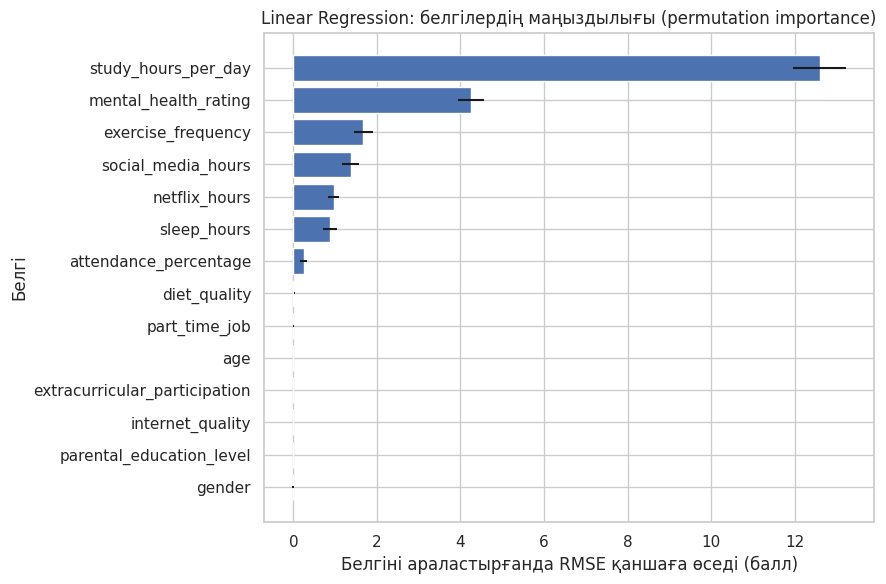

,белгі,RMSE өсуі,std
2,study_hours_per_day,12.596,0.640
12,mental_health_rating,4.249,0.316
9,exercise_frequency,1.672,0.228
3,social_media_hours,1.369,0.197
4,netflix_hours,0.964,0.134
7,sleep_hours,0.871,0.164
6,attendance_percentage,0.246,0.087
8,diet_quality,0.026,0.015
5,part_time_job,0.003,0.004
0,age,-0.003,0.004


In [28]:
pi = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                            scoring='neg_root_mean_squared_error')
imp = pd.DataFrame({'белгі': X_test.columns, 'RMSE өсуі': pi.importances_mean,
                    'std': pi.importances_std}).sort_values('RMSE өсуі', ascending=True)
plt.figure(figsize=(9, 6))
plt.barh(imp['белгі'], imp['RMSE өсуі'], xerr=imp['std'], color='#4C72B0')
plt.title(f'{BEST}: белгілердің маңыздылығы (permutation importance)')
plt.xlabel('Белгіні араластырғанда RMSE қаншаға өседі (балл)'); plt.ylabel('Белгі')
plt.tight_layout(); plt.show()
imp.sort_values('RMSE өсуі', ascending=False).round(3)

### 10.2 Linear Regression коэффициенттері (бағыт пен күшті түсіну үшін)

Сандық белгілер стандартталған, сондықтан коэффициент = белгі **1 стандартты ауытқуға** өскенде баға неше баллға өзгереді.

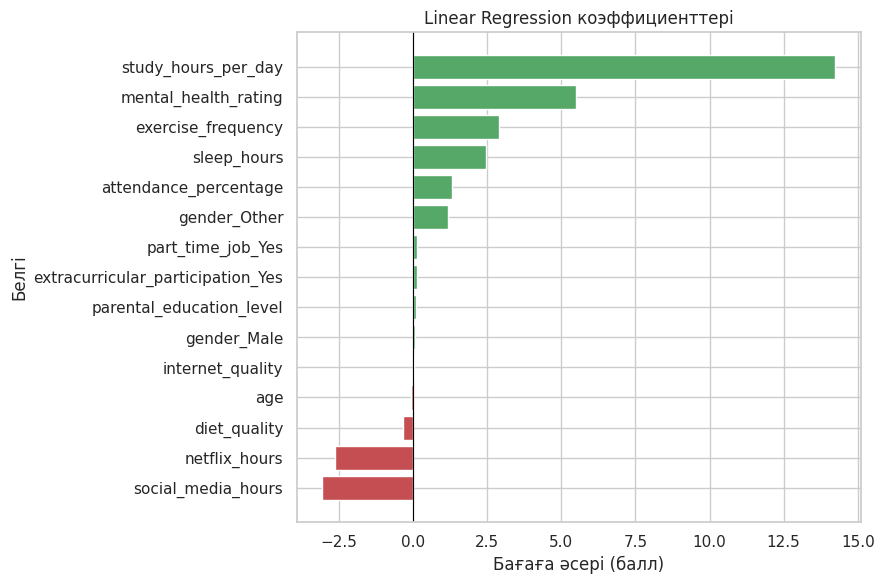

Сандық белгілердің 1 бірлікке (1 сағат, 1 балл, 1%) әсері:
social_media_hours      -2.60
netflix_hours           -2.41
age                     -0.02
attendance_percentage    0.14
exercise_frequency       1.44
mental_health_rating     1.92
sleep_hours              1.98
study_hours_per_day      9.50
dtype: float64


In [29]:
lr = best_models['Linear Regression']
coef = pd.Series(lr.named_steps['model'].estimator_.coef_, index=feature_names).sort_values()
std_map = X_train[numeric_features].std()
plt.figure(figsize=(9, 6))
plt.barh(coef.index, coef.values, color=['#C44E52' if v < 0 else '#55A868' for v in coef])
plt.title('Linear Regression коэффициенттері')
plt.xlabel('Бағаға әсері (балл)'); plt.ylabel('Белгі')
plt.axvline(0, color='black', lw=0.8)
plt.tight_layout(); plt.show()

# нақты бірліктерге аудару: 1 сағат/1 бірлік үшін әсер
per_unit = (coef[numeric_features] / std_map).round(2)
print('Сандық белгілердің 1 бірлікке (1 сағат, 1 балл, 1%) әсері:')
print(per_unit.sort_values())

### 10.3 Ішінара тәуелділік (Partial Dependence) — негізгі белгілер

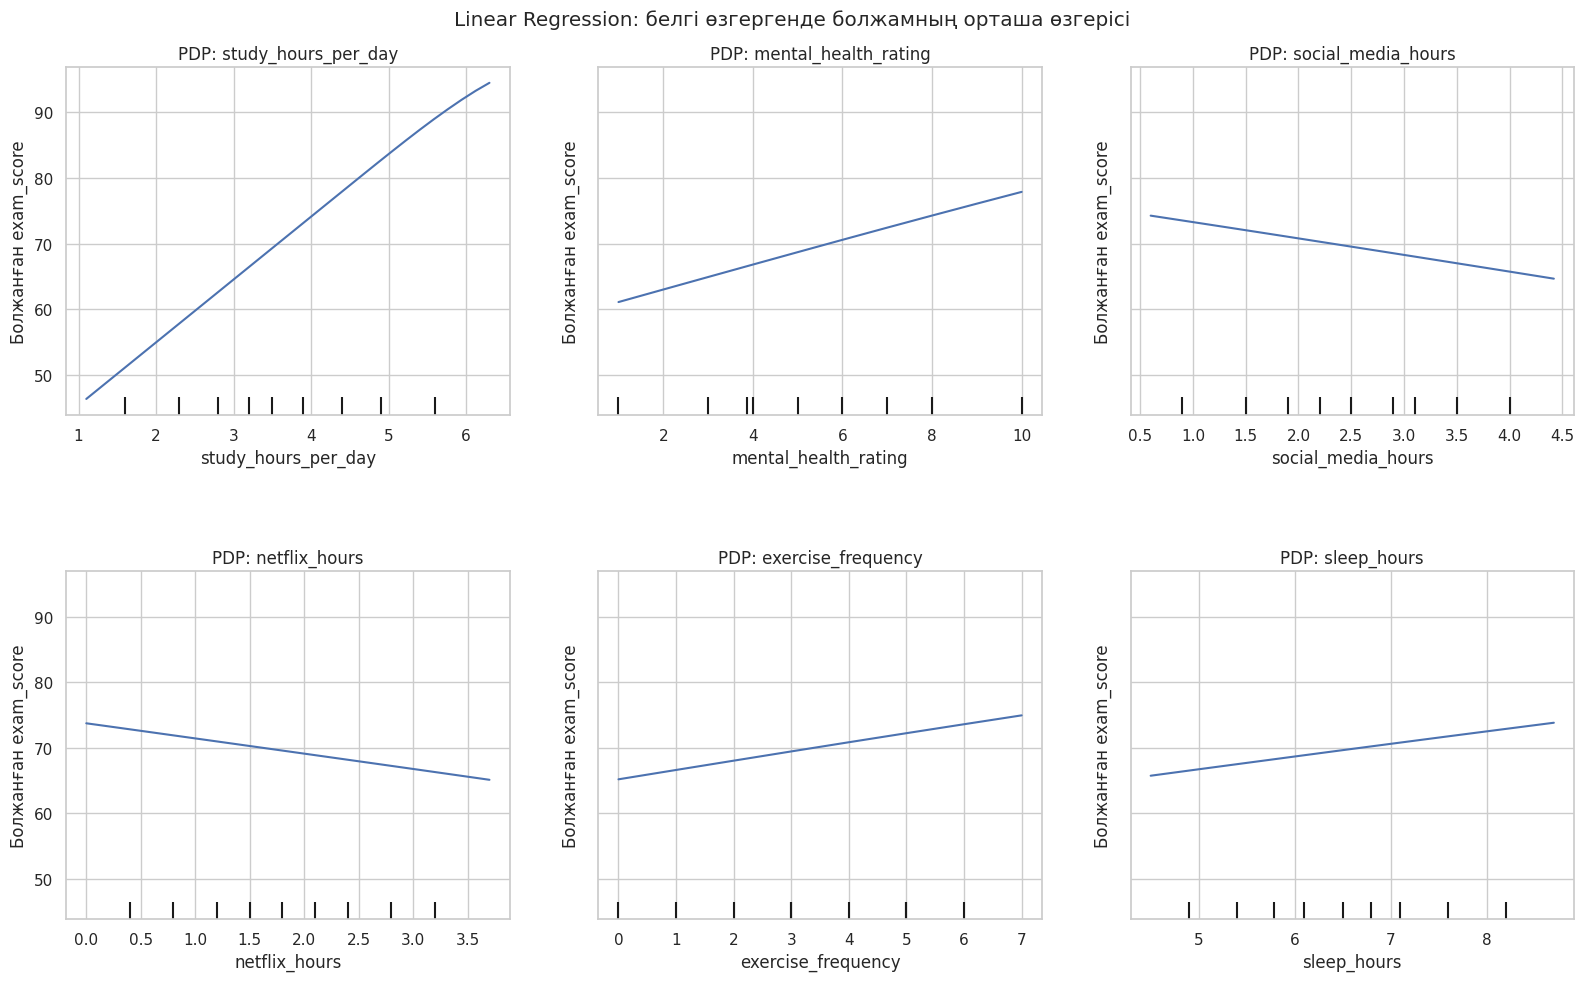

In [30]:
from sklearn.inspection import PartialDependenceDisplay
top_feats = ['study_hours_per_day', 'mental_health_rating', 'social_media_hours', 'netflix_hours',
             'exercise_frequency', 'sleep_hours']
fig, ax = plt.subplots(figsize=(16, 10))
disp = PartialDependenceDisplay.from_estimator(best, X_train, top_feats, ax=ax, n_cols=3,
                                               grid_resolution=30)
for a, f in zip(disp.axes_.ravel(), top_feats):
    a.set_ylabel('Болжанған exam_score'); a.set_xlabel(f); a.set_title(f'PDP: {f}')
fig.suptitle(f'{BEST}: белгі өзгергенде болжамның орташа өзгерісі')
plt.tight_layout(); plt.subplots_adjust(hspace=0.45); plt.show()

**Ең маңызды факторлар және олардың мағынасы:**

| Фактор | Permutation importance (RMSE өсуі) | Әсері (Linear Regression, басқа факторлар тұрақты болғанда) |
|---|---|---|
| **Оқу уақыты** | **+12.6 балл** | +1 сағат/күн → **+9.5 балл** |
| **Психикалық жағдай** | +4.2 | +1 балл (1–10 шкала) → **+1.9 балл** |
| Спорт жиілігі | +1.7 | +1 күн/апта → +1.4 балл |
| Әлеуметтік желі | +1.4 | +1 сағат → **−2.6 балл** |
| Netflix | +1.0 | +1 сағат → **−2.4 балл** |
| Ұйқы | +0.9 | +1 сағат → +2.0 балл |
| Сабаққа қатысу | +0.25 | +10% → +1.4 балл |
| Жас, жыныс, ата-ана білімі, интернет, жұмыс, үйірме, тамақтану | ≈ 0 | әсері жоқ |

**Интерпретация:**
1. **Оқу уақыты — шешуші фактор.** Оны араластырғанда модельдің қатесі 5.8-ден ≈18 баллға дейін өседі — яғни онсыз модель baseline деңгейіне түседі. Күніне 1 сағат қосымша оқу ≈ 9.5 балл береді.
2. **Психикалық жағдай — екінші маңызды фактор.** Шкаланың 1-ден 10-ға дейінгі айырмасы ≈ 17 балл береді — бұл күніне ~2 сағат қосымша оқуға тең.
3. **«Уақыт бюджеті» тұрғысынан:** 1 сағатты әлеуметтік желіден оқуға ауыстыру модель бойынша шамамен **+12 балл** береді (−(−2.6) + 9.5). Бұл студенттерге берілетін ең нақты кеңес.
4. **Өмір салты (ұйқы, спорт) кішігірім, бірақ тұрақты оң әсер береді.**
5. **Демографиялық және отбасылық белгілер бағаны болжамайды** — бұл модель студентке «тағдыры» бойынша емес, «әдеттері» бойынша баға беретінін білдіреді, бұл этикалық тұрғыдан да жақсы.

PDP графиктері де осыны көрсетеді: оқу уақытының графигі ең тік, ал басқа белгілердің графиктері жайпақ. Оқу уақытының жоғарғы ұшында қисықтың иілуі — 100 балдық шектеудің әсері.

⚠️ **Маңызды ескерту:** бұл **корреляциялық** деректер. Модель «көп оқитын студенттер жоғары баға алады» дейді, бірақ бұл себептілікті дәлелдемейді (мысалы, пәнге қызығатын студенттер көбірек оқиды әрі жақсы тапсырады). Кеңестерді «ықтимал әсер» ретінде қабылдау керек.

## 11. Жаңа деректерде тексеру

Модель оқыту кезінде көрмеген **жаңа студенттерге** болжам жасаймыз. Типтік профильдерді құрастырдық (әрқайсысы әртүрлі өмір салтын сипаттайды) — бұл модельдің практикада қалай қолданылатынын көрсетеді. Сонымен қатар тест таңдамасынан нақты бағасы белгілі 5 студентті аламыз.

In [31]:
new_students = pd.DataFrame([
    # 1. Ынталы студент: көп оқиды, экран уақыты аз, психикалық жағдайы жақсы
    dict(age=20, gender='Female', study_hours_per_day=6.0, social_media_hours=1.0, netflix_hours=0.5,
         part_time_job='No', attendance_percentage=95, sleep_hours=7.5, diet_quality='Good',
         exercise_frequency=5, parental_education_level='Master', internet_quality='Good',
         mental_health_rating=9, extracurricular_participation='Yes'),
    # 2. Орташа студент
    dict(age=21, gender='Male', study_hours_per_day=3.5, social_media_hours=2.5, netflix_hours=1.8,
         part_time_job='No', attendance_percentage=85, sleep_hours=6.5, diet_quality='Fair',
         exercise_frequency=3, parental_education_level='Bachelor', internet_quality='Average',
         mental_health_rating=5, extracurricular_participation='No'),
    # 3. Қауіп тобы: аз оқиды, экран уақыты көп, стресс
    dict(age=19, gender='Male', study_hours_per_day=1.0, social_media_hours=5.0, netflix_hours=4.0,
         part_time_job='Yes', attendance_percentage=70, sleep_hours=5.0, diet_quality='Poor',
         exercise_frequency=0, parental_education_level='High School', internet_quality='Poor',
         mental_health_rating=2, extracurricular_participation='No'),
    # 4. Көп оқиды, бірақ психикалық жағдайы нашар
    dict(age=22, gender='Female', study_hours_per_day=5.5, social_media_hours=2.0, netflix_hours=1.0,
         part_time_job='No', attendance_percentage=90, sleep_hours=5.5, diet_quality='Fair',
         exercise_frequency=1, parental_education_level='Bachelor', internet_quality='Good',
         mental_health_rating=2, extracurricular_participation='No'),
    # 5. Аз оқиды, бірақ психикалық жағдайы мен спорты жақсы
    dict(age=23, gender='Other', study_hours_per_day=2.0, social_media_hours=1.5, netflix_hours=1.0,
         part_time_job='Yes', attendance_percentage=88, sleep_hours=8.0, diet_quality='Good',
         exercise_frequency=6, parental_education_level='High School', internet_quality='Good',
         mental_health_rating=9, extracurricular_participation='Yes'),
    # 6. Деректерде бос мәндер бар (ұйқы және ата-ана білімі белгісіз) — Pipeline оларды өзі толтырады
    dict(age=20, gender='Female', study_hours_per_day=4.0, social_media_hours=3.0, netflix_hours=2.0,
         part_time_job='No', attendance_percentage=80, sleep_hours=np.nan, diet_quality='Good',
         exercise_frequency=2, parental_education_level=np.nan, internet_quality='Average',
         mental_health_rating=6, extracurricular_participation='Yes'),
])
labels = ['1. Ынталы', '2. Орташа', '3. Қауіп тобы', '4. Көп оқиды, стресс',
          '5. Аз оқиды, жағдайы жақсы', '6. Бос мәндері бар']

preds = {name: m.predict(new_students) for name, m in best_models.items()}
out = new_students[['study_hours_per_day', 'social_media_hours', 'netflix_hours',
                    'mental_health_rating', 'exercise_frequency', 'sleep_hours']].copy()
out.index = labels
out[f'Болжам ({BEST})'] = preds[BEST].round(1)
# RF-тің жеке ағаштары бойынша болжамның шашырауы — сенімділік бағасы
rf = best_models['Random Forest']
tree_preds = np.stack([t.predict(rf.named_steps['prep'].transform(new_students))
                       for t in rf.named_steps['model'].estimator_.estimators_])
out['RF болжамы'] = tree_preds.mean(0).round(1)
out['RF ағаштары 10–90 перц.'] = [f'{a:.0f}–{b:.0f}' for a, b in
                                 zip(np.percentile(tree_preds, 10, 0), np.percentile(tree_preds, 90, 0))]
out

,study_hours_per_day,social_media_hours,netflix_hours,mental_health_rating,exercise_frequency,sleep_hours,Болжам (Linear Regression),RF болжамы,RF ағаштары 10–90 перц.
1. Ынталы,6.0,1.0,0.5,9,5,7.5,100.0,97.8,90–100
2. Орташа,3.5,2.5,1.8,5,3,6.5,68.5,71.0,60–81
3. Қауіп тобы,1.0,5.0,4.0,2,0,5.0,17.9,35.5,23–47
"4. Көп оқиды, стресс",5.5,2.0,1.0,2,1,5.5,80.9,83.3,73–93
"5. Аз оқиды, жағдайы жақсы",2.0,1.5,1.0,9,6,8.0,75.1,69.7,53–80
6. Бос мәндері бар,4.0,3.0,2.0,6,2,NaN,71.0,72.5,64–81


In [32]:
sample = X_test.sample(5, random_state=7)
chk = sample[['study_hours_per_day', 'social_media_hours', 'netflix_hours',
              'mental_health_rating', 'exercise_frequency']].copy()
chk['Нақты баға'] = y_test.loc[sample.index].values
chk['Болжам'] = best.predict(sample).round(1)
chk['Қате'] = (chk['Нақты баға'] - chk['Болжам']).round(1)
chk

,study_hours_per_day,social_media_hours,netflix_hours,mental_health_rating,exercise_frequency,Нақты баға,Болжам,Қате
938,2.7,3.7,2.3,4.0,5.0,63.9,59.2,4.7
964,4.0,4.3,2.4,2.0,0.0,53.0,60.2,-7.2
664,2.8,0.2,3.1,2.0,5.0,65.6,60.5,5.1
96,4.3,3.3,0.0,9.0,6.0,94.9,93.2,1.7
394,4.8,2.1,1.9,8.0,1.0,82.6,87.3,-4.7


**Жаңа студенттерге болжам — түсініктеме:**
1. **Ынталы студент** (6 сағат оқу, экран аз, психикалық жағдайы 9): болжам **100** (шектеуге жетті). RF те 97.5 береді, ағаштардың шашырауы тар (90–100) — модельдер сенімді.
2. **Орташа студент:** болжам **68.5** — деректердегі орташа бағаға (69.6) өте жақын, бұл қисынды.
3. **Қауіп тобы** (1 сағат оқу, 9 сағат экран, психикалық жағдайы 2): Linear Regression **17.9**, RF — 35.6. Бұл профиль деректердегі ең шеткі жағдайларға жақын: сызықтық модель трендті ары қарай «созады» (экстраполяция), ал ағаштар оқыту деректеріндегі ең төмен мәндерден төмен бере алмайды. Шын мәні шамасы осы екеуінің арасында, бірақ **екі модель де бұл студентті қауіп тобы деп анықтайды** — практикалық мақсат үшін бұл ең маңыздысы: оған ертерек көмек қажет.
4. **Көп оқиды, бірақ стресс** (5.5 сағат, психикалық жағдайы 2, ұйқы аз): **80.9**. Көп оқу жоғары нәтиже береді, бірақ психикалық жағдай жақсы болса, шамамен 13 балл жоғары болар еді.
5. **Аз оқиды, бірақ өмір салты жақсы** (2 сағат, психикалық жағдайы 9, спорт 6 рет, ұйқы 8 сағат): **75.1** — 4-студенттен небәрі 6 балл төмен, бірақ 3.5 сағатқа аз оқиды. Яғни жақсы өмір салты аз оқуды ішінара өтейді. RF шашырауы кең (55–80) — модельдер мұндай сирек комбинацияда сенімсіздеу.
6. **Бос мәндері бар студент:** Pipeline ұйқы мен ата-ана білімін оқыту деректерінің медианасы/модасымен толтырып, **71.0** болжам берді — жүйе толық емес деректермен де жұмыс істейді.

**Тест таңдамасындағы 5 нақты студент:** қателер −7.2-ден +5.1-ге дейін, бәрі модельдің типтік қатесі (RMSE ≈ 5.8) шегінде. Бұл бағалау метрикаларының нақты мысалдарда да расталатынын көрсетеді.

## 12. Қорытынды

**Не зерттелді?**
986 студенттің (тазалаудан кейін) оқу әдеттері мен өмір салты негізінде емтихан бағасын (0–100) болжау және бағаға қандай факторлар әсер ететінін анықтау.

**Қандай негізгі заңдылықтар анықталды?**
- Бағаны ең күшті анықтайтын фактор — **күнделікті оқу уақыты** (r = 0.82; +1 сағат ≈ +9.5 балл). Байланыс сызықтық: 0–1 сағат оқитындардың орташасы 40, 6+ сағат — 97.5.
- **Психикалық жағдай** — екінші фактор (шкала бойынша 1→10 ≈ +17 балл).
- **Экран уақыты** бағаны төмендетеді (әр сағат ≈ −2.5 балл), ұйқы мен спорт — аздап жоғарылатады.
- Демографиялық және отбасылық белгілер (жас, жыныс, ата-ана білімі), интернет сапасы, жұмыс, үйірмелер — бағамен **байланыссыз**.

**Деректерді дайындау кезінде қандай шешімдер қабылданды және неге?**
- 20 көшірме жойылды — салмақ бұрмалануын және train/test арасындағы ағуды болдырмау үшін.
- 6 категориялық бағандағы жазылу біріздендірілді — бір категория бірнеше болып бөлінбеуі үшін.
- 31 мүмкін емес сандық мән `NaN`-ға айналдырылды (жою емес) — жолдың қалған ақпаратын сақтау үшін.
- Мақсаты жоқ/қате 13 жол және 1 аномалия (0 балл) жойылды — модель қате мақсатқа үйренбеуі үшін.
- Бос мәндер медиана/модамен **тек оқыту таңдамасы бойынша** Pipeline ішінде толтырылды — data leakage болмауы үшін.
- Реттік белгілерге OrdinalEncoder, номиналды белгілерге OneHotEncoder, болжам [0, 100] аралығына қиылды.

**Қай модель ең жақсы нәтиже көрсетті?**
**Linear Regression**: Test MAE = 4.47, RMSE = 5.75, R² = 0.883 (CV RMSE = 5.40). Gradient Boosting — екінші (R² = 0.856), Random Forest — үшінші (R² = 0.819, overfitting бар), Decision Tree — ең әлсіз (R² = 0.703).

**Неліктен таңдалған модель ең қолайлы?**
Ол тест таңдамасында да, кросс-валидацияда да барлық метрика бойынша үздік; overfitting жоқ (train/test R² айырмасы 0.02); деректердің құрылымына (сызықтық, аддитивті, өзара тәуелсіз белгілер) дәл сәйкес келеді; және әр фактордың әсерін баллмен түсіндіруге мүмкіндік береді — бұл эдвайзер үшін нақты кеңестерге айналады.

**Қандай белгілер ең маңызды болып шықты?**
`study_hours_per_day` (басым), `mental_health_rating`, одан кейін `exercise_frequency`, `social_media_hours`, `netflix_hours`, `sleep_hours`.

**Алынған шешімнің қандай шектеулері бар?**
- Деректер корреляциялық — **себеп-салдарды дәлелдемейді**.
- Деректер көлемі шағын (≈1000 студент) және әдеттер студенттің **өз бағалауымен** жиналған болуы мүмкін (дәлсіз).
- Шеткі жағдайларда (өте төмен/өте жоғары баға) қате үлкенірек; сызықтық модель шеттерде экстраполяция жасайды.
- 100 балдық шектеу («төбе әсері») ең үздік студенттерді ажыратуға мүмкіндік бермейді.
- Ең маңызды белгі (оқу уақыты) бос болса, болжам сапасы күрт төмендейді.
- Модельде алдыңғы үлгерім, пәннің қиындығы, оқу сапасы сияқты маңызды факторлар жоқ.

**Жобаны әрі қарай дамыту кезінде нені жақсартуға болады?**
- Деректерге алдыңғы семестрлердің бағаларын, пән түрін, оқу әдісінің сапасын қосу.
- Көбірек деректер жинау және оларды объективті көздерден алу (мысалы, LMS-тегі нақты белсенділік уақыты).
- Ridge/Lasso регрессиясын, белгілердің өзара әсерін (мысалы, оқу уақыты × психикалық жағдай) және болжам интервалдарын (quantile regression) сынау.
- Есепті классификация ретінде де қою («қауіп тобы: баға < 50») — эдвайзерлер үшін ыңғайлырақ нәтиже.
- Модельді веб-форма немесе дашборд түрінде енгізіп, студенттерге жеке кеңес беру құралын жасау.

## 13. Пайдаланылған дереккөздер

1. Оқытушы ұсынған деректер жиыны: `Student.csv` (Student Habits vs Academic Performance).
2. scikit-learn құжаттамасы — Pipeline, ColumnTransformer, GridSearchCV, ансамбльдік модельдер: https://scikit-learn.org/stable/user_guide.html
3. scikit-learn: Permutation feature importance — https://scikit-learn.org/stable/modules/permutation_importance.html
4. scikit-learn: Partial dependence plots — https://scikit-learn.org/stable/modules/partial_dependence.html
5. pandas құжаттамасы — https://pandas.pydata.org/docs/
6. seaborn / matplotlib құжаттамасы — https://seaborn.pydata.org/, https://matplotlib.org/
7. James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning* (2nd ed.), Springer, 2021 — регрессия, ағаштар, ансамбльдер, бағалау метрикалары.